# Experiment 1B: CLIP ViT-B/32 — Overfitting Mitigation

Compare frozen-encoder and lower-encoder-LR fine-tuning against the original CLIP baseline. Select the final checkpoint on DEV, then evaluate using the shared protocol.


## 1. Environment Setup

Import dependencies, configure the device, and set random seeds.


In [5]:
# ============================================================
# Imports
# ============================================================

# Standard libraries
import os
import json
import random
import time
import copy
import warnings
import math
from pathlib import Path
from collections import defaultdict
import gc
from fractions import Fraction

# Numerical and data processing
import numpy as np
import pandas as pd

# Image and video processing
import cv2
from PIL import Image

# PyTorch
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
from torchvision.datasets import ImageFolder

# Hugging Face CLIP
from transformers import (
    CLIPImageProcessor,
    CLIPVisionModelWithProjection
)

# Evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    auc,
    fbeta_score,
    average_precision_score,
    precision_recall_curve
)

# Visualization
import matplotlib.pyplot as plt

# Progress tracking
from tqdm.auto import tqdm

# Notebook display
from IPython.display import display

warnings.filterwarnings(
    "ignore",
    category=FutureWarning
)

import av
import sys
import importlib.util
import zipfile
from datetime import datetime, timezone

print("All imports completed successfully.")
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())


All imports completed successfully.
PyTorch version: 2.11.0+cu128
CUDA available: True


In [4]:
!pip install av

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.0/35.0 MB 60.2 MB/s eta 0:00:00:00:0100:01


In [ ]:
# ============================================================
# Reproducibility and Device Configuration
# ============================================================

SEED = 42

def set_seed(seed=42):

    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

    print(f"Random seed set to {seed}")


set_seed(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("\nDevice:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU Memory:",
        round(
            torch.cuda.get_device_properties(0).total_memory
            / 1024**3,
            2
        ),
        "GB"
    )


## 2. Dataset Preparation

Reuse the baseline frame dataset (12,000 training and 1,500 validation frames).


In [ ]:
# ============================================================
# Check Available Kaggle Datasets
# ============================================================

INPUT_ROOT = Path("/kaggle/input")

print("Available datasets:\n")

for dataset_dir in sorted(INPUT_ROOT.iterdir()):
    print(f"\n{dataset_dir.name}")

    if dataset_dir.is_dir():
        for item in list(dataset_dir.iterdir())[:8]:
            print("  ", item.name)

print("\nSearching for required files...")

frame_roots = [
    p for p in INPUT_ROOT.rglob("frames.csv")
    if (p.parent / "train").is_dir()
    and (p.parent / "val").is_dir()
]

metadata_paths = list(
    INPUT_ROOT.rglob("metadata.min.json")
)

baseline_paths = list(
    INPUT_ROOT.rglob("clip_vit_b32_best.pt")
)

print("\nFrame dataset candidates:", frame_roots)
print("Original metadata candidates:", metadata_paths)
print("Baseline checkpoint candidates:", baseline_paths)

assert len(frame_roots) == 1, "Check frame dataset path."
assert len(metadata_paths) == 1, "Check original video dataset."
assert len(baseline_paths) == 1, "Check baseline checkpoint dataset."

DATA_ROOT = frame_roots[0].parent
ORIGINAL_ROOT = metadata_paths[0].parent
BASELINE_CHECKPOINT = baseline_paths[0]

print("\nSelected paths:")
print("Frames:", DATA_ROOT)
print("Original videos:", ORIGINAL_ROOT)
print("Baseline checkpoint:", BASELINE_CHECKPOINT)


In [ ]:
# ============================================================
# CLIP Image Preprocessing and DataLoaders
# ============================================================

MODEL_NAME = "openai/clip-vit-base-patch32"

image_processor = CLIPImageProcessor.from_pretrained(
    MODEL_NAME
)

def clip_transform(image):
    pixel_values = image_processor(
        images=image,
        return_tensors="pt"
    )["pixel_values"]

    return pixel_values.squeeze(0)


train_dataset = ImageFolder(
    str(DATA_ROOT / "train"),
    transform=clip_transform
)

val_dataset = ImageFolder(
    str(DATA_ROOT / "val"),
    transform=clip_transform
)

BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

print("Class mapping:", train_dataset.class_to_idx)
print("Training frames:", len(train_dataset))
print("Validation frames:", len(val_dataset))
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

assert train_dataset.class_to_idx == {"fake": 0, "real": 1}
assert val_dataset.class_to_idx == train_dataset.class_to_idx
assert len(train_dataset) == 12000
assert len(val_dataset) == 1500

print("\nDataset preparation completed.")


## 3. Original CLIP Baseline Reference

Load the original baseline results for comparison; no baseline retraining is performed here.


In [ ]:
# ============================================================
# Verify Original Baseline Checkpoint
# ============================================================

baseline_checkpoint = torch.load(
    BASELINE_CHECKPOINT,
    map_location="cpu",
    weights_only=False
)

print("Baseline checkpoint loaded successfully.")
print("Best epoch:", baseline_checkpoint.get("epoch"))
print("Validation AUC:", baseline_checkpoint.get("val_auc"))
print("Model:", baseline_checkpoint.get("model_name"))
print("Class mapping:", baseline_checkpoint.get("class_to_idx"))

assert "model_state_dict" in baseline_checkpoint, (
    "Model weights missing from checkpoint."
)

print("\nBaseline checkpoint verified.")
print("Original model weights will remain unchanged.")


## 4. Experiment A — Frozen Vision Encoder

Freeze the CLIP vision encoder and train only the binary classification head.


In [ ]:

# ============================================================
# Experiment A: Initialize Frozen CLIP Model
# ============================================================

set_seed(SEED)

class CLIPBinaryClassifier(nn.Module):

    def __init__(self, model_name):
        super().__init__()

        self.encoder = (
            CLIPVisionModelWithProjection.from_pretrained(
                model_name
            )
        )

        self.classifier = nn.Linear(512, 2)

    def forward(self, pixel_values):

        outputs = self.encoder(
            pixel_values=pixel_values
        )

        embeddings = F.normalize(
            outputs.image_embeds,
            p=2,
            dim=-1
        )

        return self.classifier(embeddings)


frozen_model = CLIPBinaryClassifier(
    MODEL_NAME
).to(device)

# Freeze the pretrained vision encoder
for param in frozen_model.encoder.parameters():
    param.requires_grad = False

# Keep the classification head trainable
for param in frozen_model.classifier.parameters():
    param.requires_grad = True

total_params = sum(
    p.numel() for p in frozen_model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in frozen_model.parameters()
    if p.requires_grad
)

print("Total parameters:", f"{total_params:,}")
print("Trainable parameters:", f"{trainable_params:,}")
print(
    "Trainable percentage:",
    round(100 * trainable_params / total_params, 4),
    "%"
)

assert all(
    not p.requires_grad
    for p in frozen_model.encoder.parameters()
)

print("\nFrozen CLIP model initialized successfully.")


### 4.1 Training Configuration

Set up the frozen encoder, classifier, optimizer, and training controls.


In [ ]:
# ============================================================
# Experiment A: Training Configuration
# ============================================================

FROZEN_MAX_EPOCHS = 15
FROZEN_PATIENCE = 5

frozen_criterion = nn.CrossEntropyLoss()

frozen_optimizer = torch.optim.AdamW(
    frozen_model.classifier.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

FROZEN_CHECKPOINT_PATH = Path(
    "/kaggle/working/clip_frozen_encoder_best.pt"
)

frozen_history = []

frozen_best_auc = -float("inf")
frozen_best_epoch = None
frozen_epochs_without_improvement = 0

print("Frozen encoder training configuration ready.")
print("Checkpoint:", FROZEN_CHECKPOINT_PATH)


### 4.2 Training and Validation

Train the classifier and select the checkpoint using frame-level DEV ROC-AUC.


In [ ]:
# ============================================================
# Experiment A: Frozen Encoder Training
# ============================================================

for epoch in range(FROZEN_MAX_EPOCHS):

    frozen_model.train()

    # Keep frozen encoder in evaluation mode
    frozen_model.encoder.eval()

    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    train_bar = tqdm(
        train_loader,
        desc=f"Frozen Epoch {epoch+1}/{FROZEN_MAX_EPOCHS} Train",
        leave=False
    )

    for images, labels in train_bar:

        images = images.to(device)
        labels = labels.to(device)

        frozen_optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast(
            device_type=device.type,
            enabled=(device.type == "cuda")
        ):
            logits = frozen_model(images)
            loss = frozen_criterion(logits, labels)

        loss.backward()
        frozen_optimizer.step()

        train_loss_sum += loss.item() * labels.size(0)

        preds = logits.argmax(dim=1)
        train_correct += (preds == labels).sum().item()
        train_total += labels.size(0)

    train_loss = train_loss_sum / train_total
    train_acc = train_correct / train_total

    # Validation
    frozen_model.eval()

    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    val_labels = []
    val_predictions = []
    val_fake_probs = []

    with torch.no_grad():

        val_bar = tqdm(
            val_loader,
            desc=f"Frozen Epoch {epoch+1}/{FROZEN_MAX_EPOCHS} Val",
            leave=False
        )

        for images, labels in val_bar:

            images = images.to(device)
            labels = labels.to(device)

            with torch.amp.autocast(
                device_type=device.type,
                enabled=(device.type == "cuda")
            ):
                logits = frozen_model(images)
                loss = frozen_criterion(logits, labels)

            probabilities = torch.softmax(
                logits.float(), dim=1
            )

            predictions = logits.argmax(dim=1)

            val_loss_sum += loss.item() * labels.size(0)
            val_correct += (
                predictions == labels
            ).sum().item()

            val_total += labels.size(0)

            val_labels.extend(labels.cpu().numpy())
            val_predictions.extend(
                predictions.cpu().numpy()
            )
            val_fake_probs.extend(
                probabilities[:, 0].cpu().numpy()
            )

    val_loss = val_loss_sum / val_total
    val_acc = val_correct / val_total

    # ImageFolder mapping: fake=0, real=1
    val_binary_labels = (
        np.array(val_labels) == 0
    ).astype(int)

    val_binary_predictions = (
        np.array(val_predictions) == 0
    ).astype(int)

    val_f1 = f1_score(
        val_binary_labels,
        val_binary_predictions,
        zero_division=0
    )

    val_auc = roc_auc_score(
        val_binary_labels,
        val_fake_probs
    )

    frozen_history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_acc": train_acc,
        "val_loss": val_loss,
        "val_acc": val_acc,
        "val_f1": val_f1,
        "val_auc": val_auc
    })

    print(
        f"Epoch {epoch+1:02d} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"Val F1: {val_f1:.4f} | "
        f"Val AUC: {val_auc:.4f}",
        flush=True
    )

    # Save best checkpoint
    if val_auc > frozen_best_auc:

        frozen_best_auc = val_auc
        frozen_best_epoch = epoch + 1
        frozen_epochs_without_improvement = 0

        torch.save({
            "epoch": frozen_best_epoch,
            "model_state_dict": frozen_model.state_dict(),
            "val_auc": float(frozen_best_auc),
            "model_name": MODEL_NAME,
            "experiment": "frozen_encoder",
            "seed": SEED,
            "class_to_idx": train_dataset.class_to_idx
        }, FROZEN_CHECKPOINT_PATH)

        print("  -> Best frozen model saved")

    else:
        frozen_epochs_without_improvement += 1

    if frozen_epochs_without_improvement >= FROZEN_PATIENCE:
        print(
            f"\nEarly stopping after {epoch+1} epochs."
        )
        break


frozen_history_df = pd.DataFrame(frozen_history)

frozen_history_df.to_csv(
    "/kaggle/working/clip_frozen_training_history.csv",
    index=False
)

print("\nFrozen encoder training completed.")
print("Best epoch:", frozen_best_epoch)
print("Best validation ROC-AUC:", round(frozen_best_auc, 4))
print("Checkpoint:", FROZEN_CHECKPOINT_PATH)


### 4.3 Training Curves

Inspect training and validation metrics for the frozen-encoder experiment.


In [ ]:
# ============================================================
# Experiment A: Frozen Encoder Training Curves
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(17, 4))

# Loss
axes[0].plot(
    frozen_history_df["epoch"],
    frozen_history_df["train_loss"],
    marker="o",
    label="Training Loss"
)
axes[0].plot(
    frozen_history_df["epoch"],
    frozen_history_df["val_loss"],
    marker="o",
    label="Validation Loss"
)
axes[0].set_title("Frozen CLIP: Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Accuracy
axes[1].plot(
    frozen_history_df["epoch"],
    frozen_history_df["train_acc"],
    marker="o",
    label="Training Accuracy"
)
axes[1].plot(
    frozen_history_df["epoch"],
    frozen_history_df["val_acc"],
    marker="o",
    label="Validation Accuracy"
)
axes[1].set_title("Frozen CLIP: Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.3)

# Validation AUC
axes[2].plot(
    frozen_history_df["epoch"],
    frozen_history_df["val_auc"],
    marker="o",
    label="Validation ROC-AUC"
)
axes[2].set_title("Frozen CLIP: Validation ROC-AUC")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("ROC-AUC")
axes[2].legend()
axes[2].grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "/kaggle/working/clip_frozen_training_curves.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


### 4.4 Original Whole-Video DEV Evaluation

Evaluate the frozen model on the original 16-frame DEV protocol.


In [ ]:
# ============================================================
# Experiment A: Load Best Frozen Checkpoint and DEV Metadata
# ============================================================

frozen_checkpoint = torch.load(
    FROZEN_CHECKPOINT_PATH,
    map_location=device,
    weights_only=False
)

frozen_model.load_state_dict(
    frozen_checkpoint["model_state_dict"]
)

frozen_model.eval()

print("Frozen checkpoint loaded successfully.")
print("Best epoch:", frozen_checkpoint["epoch"])
print("Best frame DEV AUC:", frozen_checkpoint["val_auc"])

# Load original LAV-DF metadata
with open(ORIGINAL_ROOT / "metadata.min.json", "r") as f:
    video_metadata = json.load(f)

dev_video_items = [
    item for item in video_metadata
    if item["split"] == "dev"
]

print("\nDEV videos:", len(dev_video_items))

assert len(dev_video_items) == 500


### 4.5 Video Sampling

Sample 16 uniformly spaced frames per video (original protocol).


In [ ]:
# ============================================================
# Experiment A: Video Sampling and Prediction Functions
# ============================================================

DEV_FRAMES_PER_VIDEO = 16

def sample_dev_video_frames(video_path, n_frames=16):

    cap = cv2.VideoCapture(str(video_path))

    if not cap.isOpened():
        return []

    total_frames = int(
        cap.get(cv2.CAP_PROP_FRAME_COUNT)
    )

    if total_frames <= 0:
        cap.release()
        return []

    frame_indices = np.linspace(
        0,
        total_frames - 1,
        n_frames + 2,
        dtype=int
    )[1:-1]

    frames = []

    for frame_idx in frame_indices:

        cap.set(
            cv2.CAP_PROP_POS_FRAMES,
            int(frame_idx)
        )

        success, frame = cap.read()

        if success:
            frame = cv2.cvtColor(
                frame,
                cv2.COLOR_BGR2RGB
            )

            frames.append(
                Image.fromarray(frame)
            )

    cap.release()

    return frames


def predict_frozen_fake_probs(frames):

    if len(frames) == 0:
        return np.array([])

    batch = torch.stack([
        clip_transform(frame)
        for frame in frames
    ]).to(device)

    frozen_model.eval()

    with torch.no_grad():

        with torch.amp.autocast(
            device_type=device.type,
            enabled=(device.type == "cuda")
        ):
            logits = frozen_model(batch)

        probabilities = torch.softmax(
            logits.float(),
            dim=1
        )

        # ImageFolder mapping: fake = 0
        fake_probs = (
            probabilities[:, 0]
            .cpu()
            .numpy()
        )

    return fake_probs


print("Video sampling and prediction functions ready.")


### 4.6 DEV Predictions

Generate and save frame scores and whole-video predictions.


In [ ]:
# ============================================================
# Experiment A: Whole-Video DEV Inference
# ============================================================

frozen_dev_records = []
frozen_failed_videos = []

print("Evaluating Frozen CLIP on 500 DEV videos...")

for i, item in enumerate(dev_video_items, start=1):

    video_path = ORIGINAL_ROOT / item["file"]

    frames = sample_dev_video_frames(
        video_path,
        n_frames=DEV_FRAMES_PER_VIDEO
    )

    if len(frames) != DEV_FRAMES_PER_VIDEO:
        frozen_failed_videos.append({
            "video": item["file"],
            "frames_read": len(frames)
        })
        continue

    fake_probs = predict_frozen_fake_probs(frames)

    if len(fake_probs) != DEV_FRAMES_PER_VIDEO:
        frozen_failed_videos.append({
            "video": item["file"],
            "frames_read": len(fake_probs)
        })
        continue

    frozen_dev_records.append({
        "video": item["file"],
        "true_label": int(item["modify_video"]),
        "num_frames": len(fake_probs),
        "max_prob": float(np.max(fake_probs)),
        "mean_prob": float(np.mean(fake_probs)),
        "frame_probs": json.dumps(
            [float(p) for p in fake_probs]
        )
    })

    if i % 50 == 0:
        print(
            f"Processed {i}/{len(dev_video_items)}",
            flush=True
        )

frozen_dev_df = pd.DataFrame(frozen_dev_records)

print("\nDEV videos evaluated:", len(frozen_dev_df))
print("Failed videos:", len(frozen_failed_videos))

if frozen_failed_videos:
    display(pd.DataFrame(frozen_failed_videos))

assert len(frozen_failed_videos) == 0, (
    "Some DEV videos could not be evaluated."
)

assert len(frozen_dev_df) == 500

frozen_dev_df.to_csv(
    "/kaggle/working/clip_frozen_video_dev_predictions.csv",
    index=False
)

print("\nFrozen DEV predictions saved.")
display(frozen_dev_df.head())


### 4.7 Video-Level Results

Aggregate the 16 frame scores by **max pooling** at threshold 0.5.


In [ ]:
# ============================================================
# Experiment A: Frozen Encoder Video-Level DEV Metrics
# ============================================================

frozen_y_true = frozen_dev_df["true_label"].to_numpy()
frozen_y_score = frozen_dev_df["max_prob"].to_numpy()
frozen_y_pred = (frozen_y_score >= 0.5).astype(int)

frozen_video_metrics = {
    "model": "CLIP ViT-B/32",
    "experiment": "frozen_encoder",
    "split": "dev",
    "aggregation": "max",
    "frames_per_video": 16,
    "threshold": 0.5,
    "accuracy": float(accuracy_score(
        frozen_y_true, frozen_y_pred
    )),
    "precision": float(precision_score(
        frozen_y_true, frozen_y_pred,
        zero_division=0
    )),
    "recall": float(recall_score(
        frozen_y_true, frozen_y_pred,
        zero_division=0
    )),
    "f1": float(f1_score(
        frozen_y_true, frozen_y_pred,
        zero_division=0
    )),
    "roc_auc": float(roc_auc_score(
        frozen_y_true, frozen_y_score
    ))
}

print("Frozen CLIP Whole-Video DEV Results\n")

for key, value in frozen_video_metrics.items():
    print(f"{key}: {value}")

print("\nClassification Report:")
print(classification_report(
    frozen_y_true,
    frozen_y_pred,
    target_names=["Real", "Fake"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    frozen_y_true,
    frozen_y_pred,
    display_labels=["Real", "Fake"],
    cmap="Blues",
    values_format="d"
)

plt.title("Frozen CLIP Whole-Video DEV Confusion Matrix")
plt.tight_layout()

plt.savefig(
    "/kaggle/working/clip_frozen_video_dev_confusion_matrix.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

with open(
    "/kaggle/working/clip_frozen_video_dev_metrics.json", "w"
) as f:
    json.dump(frozen_video_metrics, f, indent=4)

print("\nFrozen DEV metrics saved.")


### 4.8 Experiment A Summary

Best epoch: **15**; frame-level DEV ROC-AUC: **0.8190**. Detailed interpretation is in the accompanying README.


## 5. Experiment B — Lower Encoder Learning Rate

Fine-tune the full CLIP model using a lower encoder learning rate to reduce overfitting.


In [ ]:
# ============================================================
# Experiment B: Initialize Lower Learning Rate CLIP
# ============================================================

# Reset random seed before model initialization
set_seed(SEED)

# Initialize independently from pretrained CLIP weights
lower_lr_model = CLIPBinaryClassifier(
    MODEL_NAME
).to(device)

# Both encoder and classifier remain trainable
for param in lower_lr_model.parameters():
    param.requires_grad = True

total_params = sum(
    p.numel() for p in lower_lr_model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in lower_lr_model.parameters()
    if p.requires_grad
)

print("Total parameters:", f"{total_params:,}")
print("Trainable parameters:", f"{trainable_params:,}")
print(
    "Trainable percentage:",
    round(100 * trainable_params / total_params, 2),
    "%"
)

assert all(
    p.requires_grad
    for p in lower_lr_model.parameters()
)

print("\nLower LR CLIP initialized successfully.")


### 5.1 Training Configuration

Use the same data and architecture as the baseline, with a reduced encoder learning rate.


In [ ]:
# ============================================================
# Experiment B: Training Configuration
# ============================================================

LOWER_LR_MAX_EPOCHS = 15
LOWER_LR_PATIENCE = 5

lower_lr_criterion = nn.CrossEntropyLoss()

lower_lr_optimizer = torch.optim.AdamW(
    [
        {
            "params": lower_lr_model.encoder.parameters(),
            "lr": 3e-6
        },
        {
            "params": lower_lr_model.classifier.parameters(),
            "lr": 1e-4
        }
    ],
    weight_decay=1e-4
)

LOWER_LR_CHECKPOINT_PATH = Path(
    "/kaggle/working/clip_lower_lr_best.pt"
)

lower_lr_history = []

lower_lr_best_auc = -float("inf")
lower_lr_best_epoch = None
lower_lr_epochs_without_improvement = 0

print("Lower LR training configuration ready.")
print("Encoder LR:", 3e-6)
print("Classifier LR:", 1e-4)
print("Checkpoint:", LOWER_LR_CHECKPOINT_PATH)


### 5.2 Training and Validation

Train and select the best checkpoint using frame-level DEV ROC-AUC.


In [ ]:
# ============================================================
# Experiment B: Lower Learning Rate Training
# ============================================================

# Mixed precision gradient scaler
lower_lr_scaler = torch.amp.GradScaler(
    "cuda",
    enabled=(device.type == "cuda")
)


for epoch in range(LOWER_LR_MAX_EPOCHS):

    lower_lr_model.train()

    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    train_bar = tqdm(
        train_loader,
        desc=f"Lower LR Epoch {epoch+1}/{LOWER_LR_MAX_EPOCHS} Train",
        leave=False
    )

    for images, labels in train_bar:

        images = images.to(device)
        labels = labels.to(device)

        lower_lr_optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast(
            device_type=device.type,
            enabled=(device.type == "cuda")
        ):
            logits = lower_lr_model(images)
            loss = lower_lr_criterion(logits, labels)

        
            # Scale loss before backward propagation
            lower_lr_scaler.scale(loss).backward()

            # Unscale gradients before clipping
            lower_lr_scaler.unscale_(lower_lr_optimizer)

            # Gradient clipping (same as original baseline)
            torch.nn.utils.clip_grad_norm_(
                lower_lr_model.parameters(),
                max_norm=1.0
            )

            # Optimizer step and scaler update
            lower_lr_scaler.step(lower_lr_optimizer)
            lower_lr_scaler.update()


        train_loss_sum += loss.item() * labels.size(0)

        preds = logits.argmax(dim=1)

        train_correct += (
            preds == labels
        ).sum().item()

        train_total += labels.size(0)

    train_loss = train_loss_sum / train_total
    train_acc = train_correct / train_total

    # ========================================================
    # Validation
    # ========================================================

    lower_lr_model.eval()

    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    val_labels = []
    val_predictions = []
    val_fake_probs = []

    with torch.no_grad():

        val_bar = tqdm(
            val_loader,
            desc=f"Lower LR Epoch {epoch+1}/{LOWER_LR_MAX_EPOCHS} Val",
            leave=False
        )

        for images, labels in val_bar:

            images = images.to(device)
            labels = labels.to(device)

            with torch.amp.autocast(
                device_type=device.type,
                enabled=(device.type == "cuda")
            ):
                logits = lower_lr_model(images)
                loss = lower_lr_criterion(logits, labels)

            probabilities = torch.softmax(
                logits.float(),
                dim=1
            )

            predictions = logits.argmax(dim=1)

            val_loss_sum += loss.item() * labels.size(0)

            val_correct += (
                predictions == labels
            ).sum().item()

            val_total += labels.size(0)

            val_labels.extend(
                labels.cpu().numpy()
            )

            val_predictions.extend(
                predictions.cpu().numpy()
            )

            # ImageFolder mapping: fake = 0
            val_fake_probs.extend(
                probabilities[:, 0].cpu().numpy()
            )

    val_loss = val_loss_sum / val_total
    val_acc = val_correct / val_total

    val_binary_labels = (
        np.array(val_labels) == 0
    ).astype(int)

    val_binary_predictions = (
        np.array(val_predictions) == 0
    ).astype(int)

    val_f1 = f1_score(
        val_binary_labels,
        val_binary_predictions,
        zero_division=0
    )

    val_auc = roc_auc_score(
        val_binary_labels,
        val_fake_probs
    )

    lower_lr_history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_acc": train_acc,
        "val_loss": val_loss,
        "val_acc": val_acc,
        "val_f1": val_f1,
        "val_auc": val_auc
    })

    print(
        f"Epoch {epoch+1:02d} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"Val F1: {val_f1:.4f} | "
        f"Val AUC: {val_auc:.4f}",
        flush=True
    )

    # ========================================================
    # Best Checkpoint Selection
    # ========================================================

    if val_auc > lower_lr_best_auc:

        lower_lr_best_auc = val_auc
        lower_lr_best_epoch = epoch + 1

        lower_lr_epochs_without_improvement = 0

        torch.save({
            "epoch": lower_lr_best_epoch,
            "model_state_dict": lower_lr_model.state_dict(),
            "val_auc": float(lower_lr_best_auc),
            "model_name": MODEL_NAME,
            "experiment": "lower_encoder_lr",
            "encoder_lr": 3e-6,
            "classifier_lr": 1e-4,
            "seed": SEED,
            "class_to_idx": train_dataset.class_to_idx
        }, LOWER_LR_CHECKPOINT_PATH)

        print("  -> Best Lower LR model saved")

    else:
        lower_lr_epochs_without_improvement += 1

    if lower_lr_epochs_without_improvement >= LOWER_LR_PATIENCE:

        print(
            f"\nEarly stopping after {epoch+1} epochs."
        )
        break


lower_lr_history_df = pd.DataFrame(lower_lr_history)

lower_lr_history_df.to_csv(
    "/kaggle/working/clip_lower_lr_training_history.csv",
    index=False
)

print("\nLower LR training completed.")
print("Best epoch:", lower_lr_best_epoch)
print(
    "Best validation ROC-AUC:",
    round(lower_lr_best_auc, 4)
)
print("Checkpoint:", LOWER_LR_CHECKPOINT_PATH)


### 5.3 Training Curves

Best epoch: **7**; frame-level DEV ROC-AUC: **0.9705**.


In [ ]:

# ============================================================
# Experiment B: Training Curves with Best Checkpoint
# ============================================================

best_epoch = lower_lr_best_epoch  # Selected by validation ROC-AUC

fig, axes = plt.subplots(1, 3, figsize=(17, 4))

# ------------------------------------------------------------
# 1. Training and Validation Loss
# ------------------------------------------------------------

axes[0].plot(
    lower_lr_history_df["epoch"],
    lower_lr_history_df["train_loss"],
    marker="o",
    label="Training Loss"
)

axes[0].plot(
    lower_lr_history_df["epoch"],
    lower_lr_history_df["val_loss"],
    marker="o",
    label="Validation Loss"
)

axes[0].set_title("Lower LR CLIP: Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

# ------------------------------------------------------------
# 2. Training and Validation Accuracy
# ------------------------------------------------------------

axes[1].plot(
    lower_lr_history_df["epoch"],
    lower_lr_history_df["train_acc"],
    marker="o",
    label="Training Accuracy"
)

axes[1].plot(
    lower_lr_history_df["epoch"],
    lower_lr_history_df["val_acc"],
    marker="o",
    label="Validation Accuracy"
)

axes[1].set_title("Lower LR CLIP: Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.3)

# ------------------------------------------------------------
# 3. Validation ROC-AUC
# ------------------------------------------------------------

axes[2].plot(
    lower_lr_history_df["epoch"],
    lower_lr_history_df["val_auc"],
    marker="o",
    label="Validation ROC-AUC"
)

axes[2].set_title("Lower LR CLIP: Validation ROC-AUC")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("ROC-AUC")
axes[2].legend()
axes[2].grid(alpha=0.3)

# ------------------------------------------------------------
# Mark selected best checkpoint on all three plots
# ------------------------------------------------------------

for ax in axes:
    ax.axvline(
        x=best_epoch,
        color="green",
        linestyle="--",
        linewidth=1.5,
        label=f"Best Checkpoint (Epoch {best_epoch})"
    )
    ax.legend()
    ax.set_xticks(lower_lr_history_df["epoch"])

plt.tight_layout()

plt.savefig(
    "/kaggle/working/clip_lower_lr_training_curves.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print(f"Selected checkpoint: Epoch {best_epoch}")
print(f"Best validation ROC-AUC: {lower_lr_best_auc:.4f}")


### 5.4 Original Whole-Video DEV Evaluation

Evaluate the Lower LR checkpoint using the original 16-frame protocol.


In [ ]:
# ============================================================
# Experiment B: Load Best Lower LR Checkpoint
# ============================================================

lower_lr_checkpoint = torch.load(
    LOWER_LR_CHECKPOINT_PATH,
    map_location=device,
    weights_only=False
)

lower_lr_model.load_state_dict(
    lower_lr_checkpoint["model_state_dict"]
)

lower_lr_model.eval()

print("Lower LR checkpoint loaded successfully.")
print("Best epoch:", lower_lr_checkpoint["epoch"])
print("Best frame DEV AUC:", lower_lr_checkpoint["val_auc"])

assert lower_lr_checkpoint["epoch"] == lower_lr_best_epoch

print("\nReady for whole-video DEV evaluation.")


### 5.5 DEV Predictions

Generate and save frame and video prediction scores.


In [ ]:

# ============================================================
# Experiment B: Whole-Video DEV Inference
# ============================================================

def predict_lower_lr_fake_probs(frames):

    if len(frames) == 0:
        return np.array([])

    batch = torch.stack([
        clip_transform(frame)
        for frame in frames
    ]).to(device)

    lower_lr_model.eval()

    with torch.no_grad():

        with torch.amp.autocast(
            device_type=device.type,
            enabled=(device.type == "cuda")
        ):
            logits = lower_lr_model(batch)

        probabilities = torch.softmax(
            logits.float(),
            dim=1
        )

        # ImageFolder class mapping: fake = 0
        fake_probs = (
            probabilities[:, 0]
            .cpu()
            .numpy()
        )

    return fake_probs


lower_lr_dev_records = []
lower_lr_failed_videos = []

print("Evaluating Lower LR CLIP on DEV videos...", flush=True)

for i, item in enumerate(dev_video_items, start=1):

    video_path = ORIGINAL_ROOT / item["file"]

    frames = sample_dev_video_frames(
        video_path,
        n_frames=DEV_FRAMES_PER_VIDEO
    )

    if len(frames) != DEV_FRAMES_PER_VIDEO:
        lower_lr_failed_videos.append({
            "video": item["file"],
            "frames_read": len(frames)
        })
        continue

    fake_probs = predict_lower_lr_fake_probs(frames)

    if len(fake_probs) != DEV_FRAMES_PER_VIDEO:
        lower_lr_failed_videos.append({
            "video": item["file"],
            "frames_read": len(fake_probs)
        })
        continue

    lower_lr_dev_records.append({
        "video": item["file"],
        "true_label": int(item["modify_video"]),
        "num_frames": len(fake_probs),
        "max_prob": float(np.max(fake_probs)),
        "mean_prob": float(np.mean(fake_probs)),
        "frame_probs": json.dumps([
            float(p) for p in fake_probs
        ])
    })

    if i % 50 == 0:
        print(
            f"Processed {i}/{len(dev_video_items)}",
            flush=True
        )


lower_lr_dev_df = pd.DataFrame(lower_lr_dev_records)

print("\nDEV videos evaluated:", len(lower_lr_dev_df))
print("Failed videos:", len(lower_lr_failed_videos))

if lower_lr_failed_videos:
    display(pd.DataFrame(lower_lr_failed_videos))

assert len(lower_lr_failed_videos) == 0, (
    "Some DEV videos could not be evaluated."
)

assert len(lower_lr_dev_df) == 500

lower_lr_dev_df.to_csv(
    "/kaggle/working/clip_lower_lr_video_dev_predictions.csv",
    index=False
)

print("\nLower LR DEV predictions saved.")
display(lower_lr_dev_df.head())


### 5.6 Video-Level Results

Use **max pooling** over 16 frames with threshold 0.5 (original protocol).


In [ ]:
# ============================================================
# Experiment B: Video-Level DEV Metrics
# ============================================================

lower_lr_y_true = lower_lr_dev_df["true_label"].to_numpy()
lower_lr_y_score = lower_lr_dev_df["max_prob"].to_numpy()
lower_lr_y_pred = (lower_lr_y_score >= 0.5).astype(int)

lower_lr_video_metrics = {
    "model": "CLIP ViT-B/32",
    "experiment": "lower_encoder_lr",
    "split": "dev",
    "aggregation": "max",
    "frames_per_video": DEV_FRAMES_PER_VIDEO,
    "threshold": 0.5,
    "accuracy": float(accuracy_score(
        lower_lr_y_true, lower_lr_y_pred
    )),
    "precision": float(precision_score(
        lower_lr_y_true, lower_lr_y_pred,
        zero_division=0
    )),
    "recall": float(recall_score(
        lower_lr_y_true, lower_lr_y_pred,
        zero_division=0
    )),
    "f1": float(f1_score(
        lower_lr_y_true, lower_lr_y_pred,
        zero_division=0
    )),
    "roc_auc": float(roc_auc_score(
        lower_lr_y_true, lower_lr_y_score
    ))
}

print("Lower LR CLIP Whole-Video DEV Results\n")

for key, value in lower_lr_video_metrics.items():
    print(f"{key}: {value}")

print("\nClassification Report:")
print(classification_report(
    lower_lr_y_true,
    lower_lr_y_pred,
    target_names=["Real", "Fake"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    lower_lr_y_true,
    lower_lr_y_pred,
    display_labels=["Real", "Fake"],
    cmap="Blues",
    values_format="d"
)

plt.title("Lower LR CLIP Whole-Video DEV Confusion Matrix")
plt.tight_layout()

plt.savefig(
    "/kaggle/working/clip_lower_lr_video_dev_confusion_matrix.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

with open(
    "/kaggle/working/clip_lower_lr_video_dev_metrics.json",
    "w"
) as f:
    json.dump(lower_lr_video_metrics, f, indent=4)

print("\nLower LR DEV metrics saved.")


## 6. Standardized DEV Evaluation

The Lower LR CLIP checkpoint (epoch 7), selected from the preliminary experiments, was re-evaluated using the shared 10 FPS PTS-based sampling, PyAV decoding, and Top-5% mean aggregation protocol.

This was an intermediate evaluation for cross-model comparison. The final CLIP model was subsequently retrained under the shared visual training protocol and is documented separately.

In [ ]:
root = Path("/kaggle/input")

for filename in [
    "dev_evaluation_candidates.sqlite",
    "data.py",
    "cnn_evaluation.py"
]:
    matches = list(root.rglob(filename))
    print(f"{filename}:")
    for path in matches:
        print(" ", path)
    if not matches:
        print("  NOT FOUND")


### 6.1 Shared DEV Index Verification

Verify 500 videos and 41,746 indexed frames (40,115 Real; 1,631 Fake).


In [ ]:
# ============================================================
# Standardized DEV: Load Shared CNN Index
# ============================================================

PROTOCOL_ROOT = Path(
    "/kaggle/input/datasets/yanhanr/cnn-standardized-dev-protocol"
)

INDEX_PATH = PROTOCOL_ROOT / "dev_evaluation_candidates.sqlite"
DATA_MODULE_PATH = PROTOCOL_ROOT / "data.py"

assert INDEX_PATH.exists()
assert DATA_MODULE_PATH.exists()

# Load the original CNN data module
spec = importlib.util.spec_from_file_location(
    "shared_cnn_data",
    DATA_MODULE_PATH
)

shared_cnn_data = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = shared_cnn_data
spec.loader.exec_module(shared_cnn_data)

# Load and verify index
shared_index = shared_cnn_data.Index(INDEX_PATH)

print("Index protocol:", shared_index.info["protocol"])

print("\nDEV index report:")
print(shared_index.report)

# Load all frame records
dev_frame_records = shared_index.records(
    split="dev",
    kind="frame"
)

print("\nDEV frame records:", len(dev_frame_records))
print(
    "Unique DEV videos:",
    len(set(r["source_file"] for r in dev_frame_records))
)

frame_labels = pd.Series(
    [r["label"] for r in dev_frame_records]
)

print("\nFrame label distribution:")
print(frame_labels.value_counts().sort_index())

assert len(dev_frame_records) == 41746
assert (frame_labels == 0).sum() == 40115
assert (frame_labels == 1).sum() == 1631

print("\nShared DEV index verified successfully!")


In [ ]:
# ============================================================
# Standardized DEV: PyAV Decoding Test
# ============================================================

# Locate original LAV-DF videos
metadata_candidates = sorted(
    Path("/kaggle/input").rglob("metadata.min.json")
)

assert len(metadata_candidates) == 1, (
    f"Expected one metadata file, found {metadata_candidates}"
)

ORIGINAL_ROOT = metadata_candidates[0].parent

print("Original video root:", ORIGINAL_ROOT)

# Select three frames from one DEV video
example_video = dev_frame_records[0]["source_file"]

example_records = [
    r for r in dev_frame_records
    if r["source_file"] == example_video
][:3]

reader = shared_cnn_data.FrameReader(
    ORIGINAL_ROOT,
    cache_mib=0
)

decoded = reader.read(example_records)

print("\nVideo:", example_video)
print("Decoded frames:", len(decoded))

for i, images in enumerate(decoded):
    print(
        f"Frame {i + 1}:",
        images[0].shape,
        "Label:",
        example_records[i]["label"]
    )

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, images, record in zip(
    axes, decoded, example_records
):
    ax.imshow(images[0])
    ax.set_title(
        f"Index {record['indices'][0]}\n"
        f"Label {record['label']}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

print("\nPyAV decoding test completed!")


In [ ]:
# ============================================================
# Standardized DEV: Load Lower LR CLIP Checkpoint
# ============================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

checkpoint_candidates = sorted(
    Path("/kaggle/input").rglob("clip_lower_lr_best.pt")
)

assert len(checkpoint_candidates) == 1, (
    f"Expected one Lower LR checkpoint, found: {checkpoint_candidates}"
)

CHECKPOINT_PATH = checkpoint_candidates[0]

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False
)

print("Checkpoint:", CHECKPOINT_PATH)
print("Best epoch:", checkpoint.get("epoch"))
print("Validation AUC:", checkpoint.get("best_val_auc"))
print("Class mapping:", checkpoint.get("class_to_idx"))

class CLIPBinaryClassifier(nn.Module):
    def __init__(self):
        super().__init__()

        self.encoder = CLIPVisionModelWithProjection.from_pretrained(
            "openai/clip-vit-base-patch32"
        )

        self.classifier = nn.Linear(512, 2)

    def forward(self, pixel_values):
        outputs = self.encoder(pixel_values=pixel_values)
        features = F.normalize(
            outputs.image_embeds,
            dim=-1
        )
        return self.classifier(features)

model = CLIPBinaryClassifier()

state_dict = checkpoint.get(
    "model_state_dict",
    checkpoint.get("model_state")
)

assert state_dict is not None, (
    "Checkpoint does not contain model weights."
)

model.load_state_dict(state_dict, strict=True)
model = model.to(device)
model.eval()

clip_processor = CLIPImageProcessor.from_pretrained(
    "openai/clip-vit-base-patch32"
)

class_mapping = checkpoint.get("class_to_idx")
assert class_mapping == {"fake": 0, "real": 1}

print("\nLower LR CLIP loaded successfully!")
print("Device:", device)
print("Model mode:", "eval" if not model.training else "train")


### 6.2 Standardized DEV Inference

Run the selected Lower LR checkpoint on the shared DEV frames and save frame/video scores.


In [ ]:
# ============================================================
# Standardized DEV: Full CLIP Frame Inference
# ============================================================

OUTPUT_ROOT = Path("/kaggle/working")
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

PROGRESS_PATH = (
    OUTPUT_ROOT / "clip_standardized_dev_progress.csv"
)

FINAL_FRAME_PATH = (
    OUTPUT_ROOT / "clip_standardized_dev_frame_predictions.csv"
)

INFERENCE_BATCH_SIZE = 32
SAVE_EVERY_VIDEOS = 10

# ------------------------------------------------------------
# 1. Group DEV records by video
# ------------------------------------------------------------

records_by_video = defaultdict(list)

for record in dev_frame_records:
    records_by_video[record["source_file"]].append(record)

video_names = sorted(records_by_video.keys())

assert len(video_names) == 500

print("Total DEV videos:", len(video_names))
print("Total DEV frames:", len(dev_frame_records))
print("Inference batch size:", INFERENCE_BATCH_SIZE)

# ------------------------------------------------------------
# 2. Load existing progress (if available)
# ------------------------------------------------------------

if PROGRESS_PATH.exists():
    progress_df = pd.read_csv(PROGRESS_PATH)

    completed_videos = set(
        progress_df["video"].unique()
    )

    prediction_rows = progress_df.to_dict("records")

    print(
        f"Resuming from {len(completed_videos)} "
        "completed videos."
    )

else:
    completed_videos = set()
    prediction_rows = []

    print("Starting new DEV inference.")

# ------------------------------------------------------------
# 3. Run inference
# ------------------------------------------------------------

model.eval()

start_time = time.time()
processed_new = 0

reader = shared_cnn_data.FrameReader(
    ORIGINAL_ROOT,
    cache_mib=0
)

for video_number, video_name in enumerate(
    video_names, 1
):

    if video_name in completed_videos:
        continue

    video_records = records_by_video[video_name]

    video_prediction_rows = []

    # Process one video in batches
    for start_idx in range(
        0,
        len(video_records),
        INFERENCE_BATCH_SIZE
    ):

        batch_records = video_records[
            start_idx:start_idx + INFERENCE_BATCH_SIZE
        ]

        # Same PyAV decoding as CNN
        decoded_batches = reader.read(
            batch_records
        )

        images = [
            Image.fromarray(frames[0])
            for frames in decoded_batches
        ]

        inputs = clip_processor(
            images=images,
            return_tensors="pt"
        )

        pixel_values = inputs[
            "pixel_values"
        ].to(device)

        with torch.inference_mode():

            logits = model(pixel_values)

            probabilities = torch.softmax(
                logits,
                dim=1
            )[:, 0]

        probabilities = (
            probabilities
            .cpu()
            .numpy()
        )

        for record, probability in zip(
            batch_records,
            probabilities
        ):

            video_prediction_rows.append({
                "video": video_name,
                "candidate_id": record["id"],
                "frame_index": record["indices"][0],
                "timestamp": float(
                    Fraction(record["timestamps_exact"][0])
                ),
                "true_label": int(
                    record["label"]
                ),
                "video_label": int(
                    record["video_label"]
                ),
                "fake_prob": float(
                    probability
                )
            })

        del decoded_batches, images, inputs
        del pixel_values, logits, probabilities

    # Only mark video complete after all its frames succeed
    assert len(video_prediction_rows) == len(
        video_records
    )

    prediction_rows.extend(
        video_prediction_rows
    )

    completed_videos.add(video_name)
    processed_new += 1

    # --------------------------------------------------------
    # 4. Save progress periodically
    # --------------------------------------------------------

    if processed_new % SAVE_EVERY_VIDEOS == 0:

        pd.DataFrame(
            prediction_rows
        ).to_csv(
            PROGRESS_PATH,
            index=False
        )

        elapsed = time.time() - start_time

        print(
            f"Completed {len(completed_videos)}/500 "
            f"videos | "
            f"Frames: {len(prediction_rows)} | "
            f"Elapsed: {elapsed/60:.1f} min",
            flush=True
        )

        gc.collect()

# ------------------------------------------------------------
# 5. Save final results
# ------------------------------------------------------------

frame_predictions_df = pd.DataFrame(
    prediction_rows
)

assert len(frame_predictions_df) == 41746

assert (
    frame_predictions_df["candidate_id"]
    .nunique()
    == 41746
)

assert (
    frame_predictions_df["video"]
    .nunique()
    == 500
)

frame_predictions_df = (
    frame_predictions_df
    .sort_values(["video", "frame_index"])
    .reset_index(drop=True)
)

frame_predictions_df.to_csv(
    FINAL_FRAME_PATH,
    index=False
)

print("\nStandardized DEV inference completed!")
print("Total frames:", len(frame_predictions_df))
print("Total videos:", frame_predictions_df["video"].nunique())
print("Saved:", FINAL_FRAME_PATH)


In [ ]:
# ============================================================
# Standardized DEV: Frame-level Metrics
# ============================================================

frame_y_true = frame_predictions_df[
    "true_label"
].to_numpy(dtype=int)

frame_y_score = frame_predictions_df[
    "fake_prob"
].to_numpy(dtype=float)

FRAME_THRESHOLD = 0.5

frame_y_pred = (
    frame_y_score >= FRAME_THRESHOLD
).astype(int)

frame_metrics = {
    "accuracy": accuracy_score(
        frame_y_true, frame_y_pred
    ),
    "precision": precision_score(
        frame_y_true, frame_y_pred,
        zero_division=0
    ),
    "recall": recall_score(
        frame_y_true, frame_y_pred,
        zero_division=0
    ),
    "f1": f1_score(
        frame_y_true, frame_y_pred,
        zero_division=0
    ),
    "f2": fbeta_score(
        frame_y_true, frame_y_pred,
        beta=2,
        zero_division=0
    ),
    "roc_auc": roc_auc_score(
        frame_y_true, frame_y_score
    ),
    "average_precision": average_precision_score(
        frame_y_true, frame_y_score
    )
}

print("Standardized CLIP Frame-level DEV Results\n")

for key, value in frame_metrics.items():
    print(f"{key}: {value:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        frame_y_true,
        frame_y_pred,
        target_names=["Real", "Fake"],
        zero_division=0
    )
)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        frame_y_true,
        frame_y_pred
    )
)


In [ ]:
# ============================================================
# Standardized DEV: Top-5% Video Aggregation
# ============================================================

video_prediction_rows = []

for video_name, group in frame_predictions_df.groupby(
    "video",
    sort=True
):

    probabilities = np.sort(
        group["fake_prob"].to_numpy(dtype=float)
    )[::-1]

    n_frames = len(probabilities)

    k = max(
        1,
        math.ceil(n_frames * 0.05)
    )

    video_score = float(
        probabilities[:k].mean()
    )

    video_prediction_rows.append({
        "video": video_name,
        "true_label": int(
            group["video_label"].iloc[0]
        ),
        "top5_prob": video_score,
        "frames": n_frames,
        "top_k": k
    })

video_predictions_df = pd.DataFrame(
    video_prediction_rows
)

assert len(video_predictions_df) == 500

VIDEO_PREDICTIONS_PATH = (
    OUTPUT_ROOT / "clip_standardized_dev_video_predictions.csv"
)

video_predictions_df.to_csv(
    VIDEO_PREDICTIONS_PATH,
    index=False
)

print("Top-5% video aggregation completed!")
print("Videos:", len(video_predictions_df))

display(
    video_predictions_df.head()
)

print("\nSaved:", VIDEO_PREDICTIONS_PATH)


In [ ]:

# ============================================================
# Standardized DEV: Video-level Metrics
# ============================================================

video_y_true = video_predictions_df[
    "true_label"
].to_numpy(dtype=int)

video_y_score = video_predictions_df[
    "top5_prob"
].to_numpy(dtype=float)

VIDEO_THRESHOLD = 0.5

video_y_pred = (
    video_y_score >= VIDEO_THRESHOLD
).astype(int)

video_metrics = {
    "accuracy": accuracy_score(
        video_y_true, video_y_pred
    ),
    "precision": precision_score(
        video_y_true, video_y_pred,
        zero_division=0
    ),
    "recall": recall_score(
        video_y_true, video_y_pred,
        zero_division=0
    ),
    "f1": f1_score(
        video_y_true, video_y_pred,
        zero_division=0
    ),
    "f2": fbeta_score(
        video_y_true, video_y_pred,
        beta=2,
        zero_division=0
    ),
    "roc_auc": roc_auc_score(
        video_y_true, video_y_score
    ),
    "average_precision": average_precision_score(
        video_y_true, video_y_score
    )
}

print("Standardized CLIP Whole-video DEV Results\n")

for key, value in video_metrics.items():
    print(f"{key}: {value:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        video_y_true,
        video_y_pred,
        target_names=["Real", "Fake"],
        zero_division=0
    )
)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        video_y_true,
        video_y_pred
    )
)


In [ ]:
# ============================================================
# Standardized DEV: Confusion Matrices
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

for ax, y_true, y_pred, title in [
    (
        axes[0],
        frame_y_true,
        frame_y_pred,
        "CLIP Frame-level DEV"
    ),
    (
        axes[1],
        video_y_true,
        video_y_pred,
        "CLIP Video-level DEV"
    )
]:
    cm = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Real", "Fake"]
    )

    disp.plot(
        ax=ax,
        cmap="Blues",
        colorbar=False,
        values_format="d"
    )

    ax.set_title(title + " (Threshold = 0.5)")

plt.tight_layout()

plt.savefig(
    "/kaggle/working/clip_standardized_dev_confusion_matrices.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


In [ ]:
# ============================================================
# Standardized DEV: ROC and PR Curves
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for label, y_true, y_score in [
    ("Frame", frame_y_true, frame_y_score),
    ("Video", video_y_true, video_y_score)
]:

    fpr, tpr, _ = roc_curve(y_true, y_score)

    precision, recall, _ = precision_recall_curve(
        y_true, y_score
    )

    roc_value = roc_auc_score(y_true, y_score)
    ap_value = average_precision_score(y_true, y_score)
    pr_auc_value = auc(recall, precision)

    axes[0].plot(
        fpr, tpr,
        linewidth=2,
        label=f"{label} (AUC={roc_value:.4f})"
    )

    axes[1].plot(
        recall, precision,
        linewidth=2,
        label=f"{label} (PR-AUC={pr_auc_value:.4f})"
    )

    print(
        f"{label}: ROC-AUC={roc_value:.4f}, "
        f"PR-AUC={pr_auc_value:.4f}, "
        f"AP={ap_value:.4f}"
    )

axes[0].plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray"
)

axes[0].set_title("CLIP DEV ROC Curves")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].set_title("CLIP DEV Precision-Recall Curves")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "/kaggle/working/clip_standardized_dev_roc_pr_curves.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


## 7. Standardized DEV Threshold Analysis

Sweep video thresholds from 0.05 to 0.95 using saved Top-5% DEV scores. Select by **video F1**; report F2 as supplementary. No TEST-based tuning.


In [ ]:
# ============================================================
# Standardized DEV: Load Video Predictions for Threshold Analysis
# ============================================================

OUTPUT_ROOT = Path("/kaggle/working")

DEV_PREDICTIONS_PATH = (
    OUTPUT_ROOT / "clip_standardized_dev_video_predictions.csv"
)

assert DEV_PREDICTIONS_PATH.exists(), (
    "Standardized DEV predictions not found. "
    "Restore the saved CSV before continuing."
)

threshold_dev_df = pd.read_csv(DEV_PREDICTIONS_PATH)

required_columns = {
    "video", "true_label", "top5_prob"
}

assert required_columns.issubset(threshold_dev_df.columns)
assert len(threshold_dev_df) == 500
assert threshold_dev_df["video"].nunique() == 500

threshold_y_true = threshold_dev_df[
    "true_label"
].to_numpy(dtype=int)

threshold_y_score = threshold_dev_df[
    "top5_prob"
].to_numpy(dtype=float)

assert np.isfinite(threshold_y_score).all()
assert np.all(
    (threshold_y_score >= 0) &
    (threshold_y_score <= 1)
)

assert np.bincount(
    threshold_y_true, minlength=2
).tolist() == [250, 250]

original_predictions = (
    threshold_y_score >= 0.5
).astype(int)

print("Standardized DEV predictions loaded!")
print("Videos:", len(threshold_dev_df))
print("Aggregation: Top-5% Mean")

print("\nReference threshold = 0.5")
print("Accuracy:", round(
    accuracy_score(threshold_y_true, original_predictions), 4
))
print("F1:", round(
    f1_score(threshold_y_true, original_predictions), 4
))
print("F2:", round(
    fbeta_score(threshold_y_true, original_predictions, beta=2), 4
))
print("ROC-AUC:", round(
    roc_auc_score(threshold_y_true, threshold_y_score), 4
))

assert np.isclose(
    accuracy_score(threshold_y_true, original_predictions),
    0.8200
)
assert np.isclose(
    roc_auc_score(threshold_y_true, threshold_y_score),
    0.8946,
    atol=0.0001
)


### 7.1 Threshold Comparison

Compare precision, recall, F1, F2, and classification errors across thresholds.


In [ ]:
# ============================================================
# Standardized DEV: Threshold Comparison
# ============================================================

threshold_values = np.round(
    np.arange(0.05, 0.951, 0.01), 2
)

threshold_results = []

for threshold in threshold_values:
    predictions = (
        threshold_y_score >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        threshold_y_true,
        predictions,
        labels=[0, 1]
    ).ravel()

    threshold_results.append({
        "threshold": float(threshold),
        "accuracy": accuracy_score(
            threshold_y_true, predictions
        ),
        "precision": precision_score(
            threshold_y_true, predictions, zero_division=0
        ),
        "recall": recall_score(
            threshold_y_true, predictions, zero_division=0
        ),
        "f1": f1_score(
            threshold_y_true, predictions, zero_division=0
        ),
        "f2": fbeta_score(
            threshold_y_true, predictions,
            beta=2, zero_division=0
        ),
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp)
    })

threshold_results_df = pd.DataFrame(threshold_results)

selected_thresholds = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]

print("Standardized DEV Threshold Comparison:")
display(
    threshold_results_df[
        threshold_results_df["threshold"].isin(selected_thresholds)
    ].round(4)
)

threshold_results_df.to_csv(
    OUTPUT_ROOT / "clip_standardized_dev_threshold_analysis.csv",
    index=False
)


### 7.2 Threshold Sensitivity Plots

Visualize metric and error-count changes, including the reference threshold 0.5.


In [ ]:
# ============================================================
# Standardized DEV: Threshold Sensitivity Plots
# ============================================================

# Deterministic tie-break: choose threshold closest to 0.5
max_f1 = threshold_results_df["f1"].max()

f1_candidates = threshold_results_df[
    np.isclose(threshold_results_df["f1"], max_f1)
].copy()

f1_candidates["distance_from_half"] = (
    f1_candidates["threshold"] - 0.5
).abs()

best_threshold_row = f1_candidates.sort_values(
    ["distance_from_half", "threshold"]
).iloc[0]

selected_threshold = float(best_threshold_row["threshold"])

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for metric in ["accuracy", "precision", "recall", "f1", "f2"]:
    axes[0].plot(
        threshold_results_df["threshold"],
        threshold_results_df[metric],
        label=metric.upper() if metric in ("f1", "f2")
              else metric.capitalize(),
        linewidth=2
    )

axes[0].set_title("CLIP Standardized DEV: Threshold vs. Metrics")
axes[0].set_xlabel("Video Classification Threshold")
axes[0].set_ylabel("Score")
axes[0].set_ylim(0, 1.05)

for metric in ["fp", "fn"]:
    axes[1].plot(
        threshold_results_df["threshold"],
        threshold_results_df[metric],
        label="False Positives" if metric == "fp"
              else "False Negatives",
        linewidth=2
    )

axes[1].set_title("CLIP Standardized DEV: Classification Errors")
axes[1].set_xlabel("Video Classification Threshold")
axes[1].set_ylabel("Number of Videos")

for ax in axes:
    ax.axvline(
        0.5, color="black", linestyle="--",
        label="Reference = 0.5"
    )
    ax.axvline(
        selected_threshold, color="red", linestyle=":",
        label=f"DEV-selected F1 = {selected_threshold:.2f}"
    )
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    OUTPUT_ROOT / "clip_standardized_dev_threshold_curves.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()


### 7.3 Locked Threshold

DEV-selected video threshold: **0.35** (F1 = **0.8436**).


In [ ]:
# ============================================================
# Standardized DEV: Final Threshold Selection
# ============================================================

reference_row = threshold_results_df[
    np.isclose(threshold_results_df["threshold"], 0.5)
].iloc[0]

best_f2_row = threshold_results_df.loc[
    threshold_results_df["f2"].idxmax()
]

print("Reference threshold = 0.5")
print(reference_row[
    ["accuracy", "precision", "recall", "f1", "f2", "fp", "fn"]
].to_string())

print("\nSelected DEV F1 Threshold")
print(best_threshold_row[
    ["threshold", "accuracy", "precision",
     "recall", "f1", "f2", "fp", "fn"]
].to_string())

print("\nBest DEV F2 Threshold (Supplementary)")
print(best_f2_row[
    ["threshold", "f1", "f2", "precision", "recall"]
].to_string())

print(
    "\nDEV F1 improvement:",
    round(float(best_threshold_row["f1"] - reference_row["f1"]), 4)
)

selected_config = {
    "model": "CLIP ViT-B/32",
    "experiment": "lower_encoder_lr",
    "checkpoint": "clip_lower_lr_best.pt",
    "best_epoch": 7,
    "sampling": "shared_10fps_pts",
    "aggregation": "top5_mean",
    "topk_fraction": 0.05,
    "threshold_selection": "maximize_dev_video_f1",
    "tie_break": "closest_to_0.5_then_lower",
    "video_threshold": selected_threshold,
    "reference_threshold": 0.5,
    "dev_video_roc_auc": 0.8946,
    "dev_video_pr_auc": 0.8853
}

CONFIG_PATH = (
    OUTPUT_ROOT / "clip_standardized_selected_config.json"
)

with open(CONFIG_PATH, "w") as f:
    json.dump(selected_config, f, indent=2)

print("\nSelected configuration saved:", CONFIG_PATH)
print("Final video threshold:", selected_threshold)


## 8. CLIP Grad-CAM Demonstration

Visualize a small, fixed DEV subset (TP/TN/FP/FN) with ViT-compatible Grad-CAM. Attribution is qualitative, not a manipulation mask.


In [18]:
# ============================================================
# CLIP Grad-CAM: Load DEV Predictions
# ============================================================

DEV_FRAME_NAME = "clip_standardized_dev_frame_predictions.csv"

matches = [
    p for p in [
        OUTPUT_ROOT / DEV_FRAME_NAME,
        *Path("/kaggle/input").rglob(DEV_FRAME_NAME)
    ]
    if p.exists()
]

assert len(matches) == 1, (
    f"Expected one DEV frame predictions CSV, found: {matches}"
)

gradcam_dev_df = pd.read_csv(matches[0])

assert len(gradcam_dev_df) == 41746
assert gradcam_dev_df["candidate_id"].nunique() == 41746

# Frame-level reporting threshold
GRADCAM_FRAME_THRESHOLD = 0.5

gradcam_dev_df["pred_label"] = (
    gradcam_dev_df["fake_prob"] >= GRADCAM_FRAME_THRESHOLD
).astype(int)

gradcam_dev_df["category"] = np.select(
    [
        (gradcam_dev_df["true_label"] == 1) &
        (gradcam_dev_df["pred_label"] == 1),

        (gradcam_dev_df["true_label"] == 0) &
        (gradcam_dev_df["pred_label"] == 0),

        (gradcam_dev_df["true_label"] == 0) &
        (gradcam_dev_df["pred_label"] == 1),

        (gradcam_dev_df["true_label"] == 1) &
        (gradcam_dev_df["pred_label"] == 0)
    ],
    ["TP", "TN", "FP", "FN"],
    default="Unknown"
)

print("Available DEV examples:")
print(gradcam_dev_df["category"].value_counts())

# Fixed-seed representative sampling
selected_examples = []

for category in ["TP", "TN", "FP", "FN"]:
    subset = gradcam_dev_df[
        gradcam_dev_df["category"] == category
    ]

    assert len(subset) > 0, f"No {category} examples"

    selected_examples.append(
        subset.sample(n=1, random_state=42).iloc[0]
    )

gradcam_examples_df = pd.DataFrame(selected_examples)

display(
    gradcam_examples_df[
        ["video", "frame_index", "true_label",
         "fake_prob", "category"]
    ]
)


Available DEV examples:
category
TN    37124
FP     2991
TP     1277
FN      354
Name: count, dtype: int64


,video,frame_index,true_label,fake_prob,category
12051,dev/054904.mp4,105,1,0.990947,TP
41394,dev/133896.mp4,47,0,0.008871,TN
17211,dev/062452.mp4,27,0,0.985467,FP
27087,dev/100142.mp4,52,1,0.009528,FN


In [19]:
# ============================================================
# CLIP ViT-B/32: Grad-CAM Implementation
# ============================================================

class CLIPViTGradCAM:
    def __init__(self, model):
        self.model = model
        self.activations = None

        # Intermediate Transformer layer:
        # patch-token gradients remain connected to CLS output.
        self.target_layer = (
            model.encoder.vision_model.encoder.layers[-2].layer_norm1
        )

    def _capture(self, module, inputs, output):
        self.activations = output

    def generate(self, pixel_values):

        self.model.eval()
        self.activations = None

        handle = self.target_layer.register_forward_hook(
            self._capture
        )

        try:
            with torch.enable_grad():
                pixels = (
                    pixel_values.detach()
                    .clone()
                    .float()
                    .requires_grad_(True)
                )

                logits = self.model(pixels)

                # Fake class index = 0
                fake_logit = logits[:, 0].sum()

                assert self.activations is not None

                gradients = torch.autograd.grad(
                    fake_logit,
                    self.activations
                )[0]

                # Remove CLS token
                activations = self.activations[:, 1:, :]
                gradients = gradients[:, 1:, :]

                n_patches = activations.shape[1]
                grid_size = math.isqrt(n_patches)

                assert grid_size * grid_size == n_patches

                # Gradient weights per channel
                weights = gradients.mean(
                    dim=1, keepdim=True
                )

                cam = (
                    activations * weights
                ).sum(dim=-1)

                cam = F.relu(cam)

                cam = cam.reshape(
                    -1, 1, grid_size, grid_size
                )

                cam = F.interpolate(
                    cam,
                    size=(224, 224),
                    mode="bilinear",
                    align_corners=False
                )

                cam = cam[:, 0]

                cam_max = cam.flatten(1).amax(
                    dim=1
                ).view(-1, 1, 1)

                cam = torch.where(
                    cam_max > 0,
                    cam / cam_max.clamp_min(1e-8),
                    torch.zeros_like(cam)
                )

                fake_prob = torch.softmax(
                    logits, dim=1
                )[:, 0]

                return (
                    cam.detach().cpu().numpy(),
                    fake_prob.detach().cpu().numpy()
                )

        finally:
            handle.remove()
            self.activations = None


gradcam_generator = CLIPViTGradCAM(model)

print("CLIP ViT Grad-CAM initialized.")
print("Target layer: penultimate Transformer block layer_norm1")


CLIP ViT Grad-CAM initialized.
Target layer: penultimate Transformer block layer_norm1


TP: saved=0.9909, Grad-CAM inference=0.9909, difference=0.000000


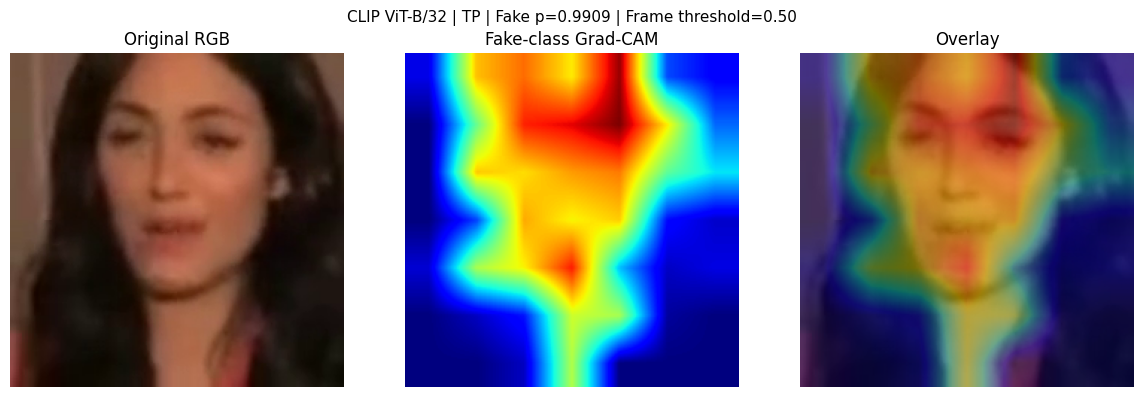

TN: saved=0.0089, Grad-CAM inference=0.0089, difference=0.000000


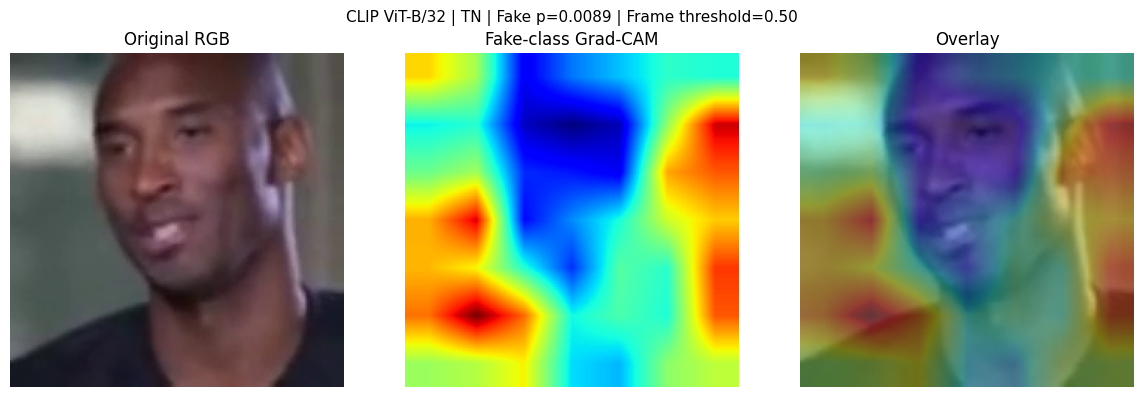

FP: saved=0.9855, Grad-CAM inference=0.9855, difference=0.000000


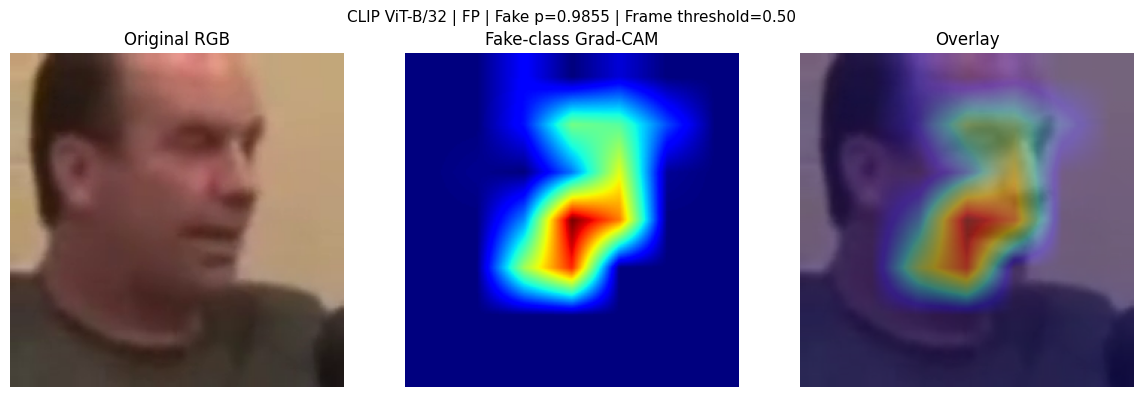

FN: saved=0.0095, Grad-CAM inference=0.0095, difference=0.000000


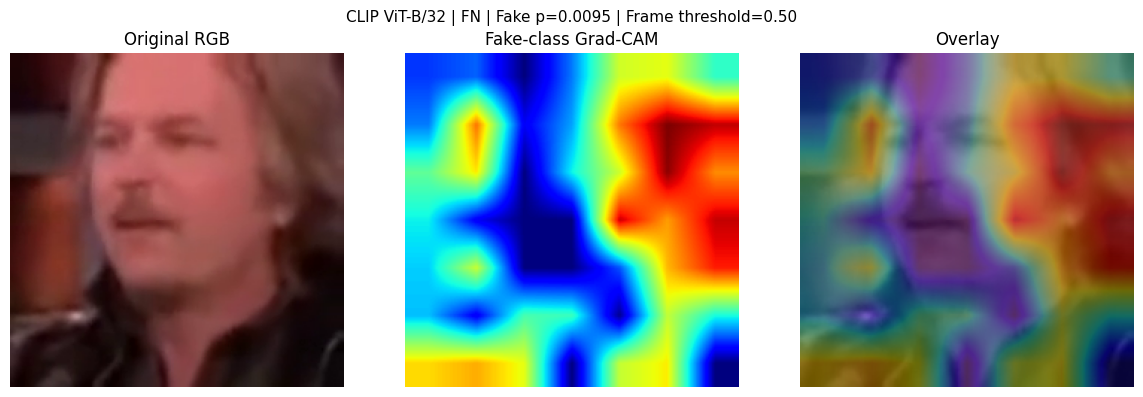


Grad-CAM demo completed!
Figures saved in: /kaggle/working/clip_gradcam_dev


In [ ]:
# ============================================================
# CLIP Grad-CAM: Generate Representative DEV Figures
# ============================================================

GRADCAM_OUTPUT = OUTPUT_ROOT / "clip_gradcam_dev"
GRADCAM_OUTPUT.mkdir(parents=True, exist_ok=True)

# Restore shared DEV index
if "dev_frame_records" not in globals():
    shared_index = shared_cnn_data.Index(
        PROTOCOL_ROOT / "dev_evaluation_candidates.sqlite"
    )
    dev_frame_records = shared_index.records("dev", "frame")

records_lookup = {
    int(r["id"]): r
    for r in dev_frame_records
}

# DEV-only PyAV reader
reader = shared_cnn_data.FrameReader(
    ORIGINAL_ROOT,
    cache_mib=0
)

saved_rows = []

for _, example in gradcam_examples_df.iterrows():

    record = records_lookup[int(example["candidate_id"])]

    # Exact indexed frame
    original_rgb = reader.read([record])[0][0]
    image = Image.fromarray(original_rgb)

    inputs = clip_processor(
        images=[image],
        return_tensors="pt"
    )

    pixel_values = inputs["pixel_values"].to(device)

    heatmaps, probabilities = gradcam_generator.generate(
        pixel_values
    )

    heatmap = heatmaps[0]
    fake_prob = float(probabilities[0])

    # Check model output against saved inference
    saved_prob = float(example["fake_prob"])
    difference = abs(fake_prob - saved_prob)

    print(
        f"{example['category']}: "
        f"saved={saved_prob:.4f}, "
        f"Grad-CAM inference={fake_prob:.4f}, "
        f"difference={difference:.6f}"
    )

    if difference > 0.01:
        print("WARNING: Prediction differs from saved DEV score.")

    # Heatmap overlay
    color_map = plt.get_cmap("jet")(heatmap)[..., :3]

    overlay = np.clip(
        0.6 * original_rgb.astype(float) / 255.0
        + 0.4 * color_map,
        0, 1
    )

    fig, axes = plt.subplots(1, 3, figsize=(12, 4))

    axes[0].imshow(original_rgb)
    axes[0].set_title("Original RGB")

    axes[1].imshow(
        heatmap, cmap="jet", vmin=0, vmax=1
    )
    axes[1].set_title("Fake-class Grad-CAM")

    axes[2].imshow(overlay)
    axes[2].set_title("Overlay")

    for ax in axes:
        ax.axis("off")

    category = example["category"]

    fig.suptitle(
        f"CLIP ViT-B/32 | {category} | "
        f"Fake p={fake_prob:.4f} | "
        f"Frame threshold=0.50",
        fontsize=11
    )

    plt.tight_layout()

    output_path = (
        GRADCAM_OUTPUT /
        f"clip_gradcam_{category.lower()}.png"
    )

    plt.savefig(
        output_path,
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    saved_rows.append({
        "category": category,
        "video": example["video"],
        "candidate_id": int(example["candidate_id"]),
        "frame_index": int(example["frame_index"]),
        "true_label": int(example["true_label"]),
        "saved_fake_prob": saved_prob,
        "gradcam_fake_prob": fake_prob,
        "difference": difference,
        "figure": str(output_path)
    })

gradcam_report_df = pd.DataFrame(saved_rows)

gradcam_report_df.to_csv(
    GRADCAM_OUTPUT / "gradcam_examples.csv",
    index=False
)

print("\nGrad-CAM demo completed!")
print("Figures saved in:", GRADCAM_OUTPUT)


### 8.1 Top-5% Video Contributors

Visualize two high-scoring DEV frames contributing to one correctly detected Fake video.


In [21]:
# ============================================================
# CLIP Grad-CAM: Select Top-5% Video Contributors
# ============================================================

DEV_VIDEO_NAME = "clip_standardized_dev_video_predictions.csv"

video_candidates = [
    p for p in [
        OUTPUT_ROOT / DEV_VIDEO_NAME,
        *Path("/kaggle/input").rglob(DEV_VIDEO_NAME)
    ]
    if p.exists()
]

assert len(video_candidates) == 1, (
    f"Expected one DEV video predictions CSV, found {video_candidates}"
)

gradcam_video_df = pd.read_csv(video_candidates[0])

VIDEO_THRESHOLD = 0.35

# Correctly detected Fake videos
tp_videos = gradcam_video_df[
    (gradcam_video_df["true_label"] == 1) &
    (gradcam_video_df["top5_prob"] >= VIDEO_THRESHOLD)
].copy()

assert len(tp_videos) > 0

# Deterministic example: highest video Fake probability
selected_video = tp_videos.sort_values(
    ["top5_prob", "video"],
    ascending=[False, True]
).iloc[0]

selected_video_name = selected_video["video"]

print("Selected DEV Fake video:", selected_video_name)
print("Video Fake probability:", selected_video["top5_prob"])
print("Video threshold:", VIDEO_THRESHOLD)
print("Number of frames:", selected_video["frames"])
print("Top-k frames:", selected_video["top_k"])

# Retrieve all saved frame predictions for this video
video_frame_candidates = gradcam_dev_df[
    gradcam_dev_df["video"] == selected_video_name
].copy()

assert len(video_frame_candidates) == int(selected_video["frames"])

# Exact Top-5% contributor count
k = max(
    1,
    math.ceil(len(video_frame_candidates) * 0.05)
)

top5_frames = video_frame_candidates.sort_values(
    ["fake_prob", "frame_index"],
    ascending=[False, True]
).head(k)

# Verify aggregation matches saved video score
recomputed_video_score = top5_frames["fake_prob"].mean()

assert np.isclose(
    recomputed_video_score,
    selected_video["top5_prob"],
    atol=1e-6
)

# Select up to two top contributors for visualization
selected_contributors = top5_frames.head(2)

print("\nSelected Top-5% contributing frames:")
display(
    selected_contributors[
        ["video", "frame_index", "true_label", "fake_prob"]
    ]
)

print("\nRecomputed Video Score:", recomputed_video_score)


Selected DEV Fake video: dev/067536.mp4
Video Fake probability: 0.9912446498870848
Video threshold: 0.35
Number of frames: 87
Top-k frames: 5

Selected Top-5% contributing frames:


,video,frame_index,true_label,fake_prob
18823,dev/067536.mp4,30,1,0.991252
18822,dev/067536.mp4,27,1,0.991251



Recomputed Video Score: 0.9912446498870849


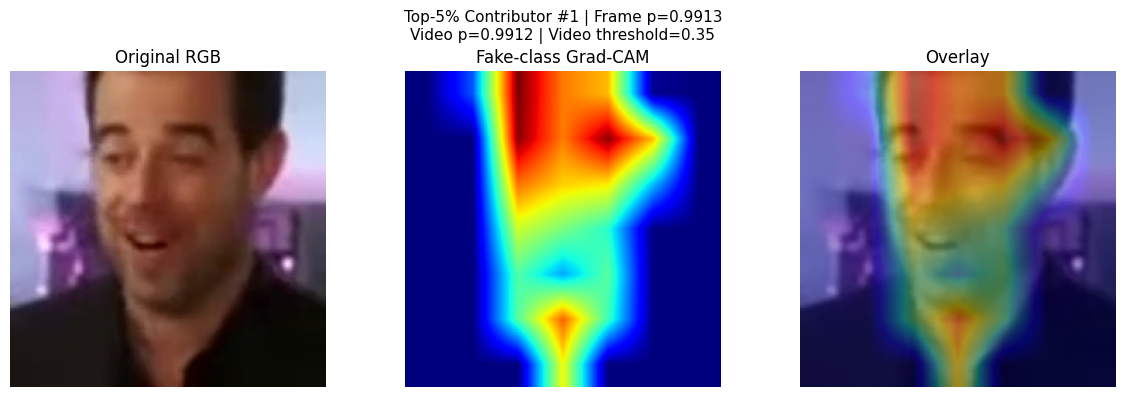

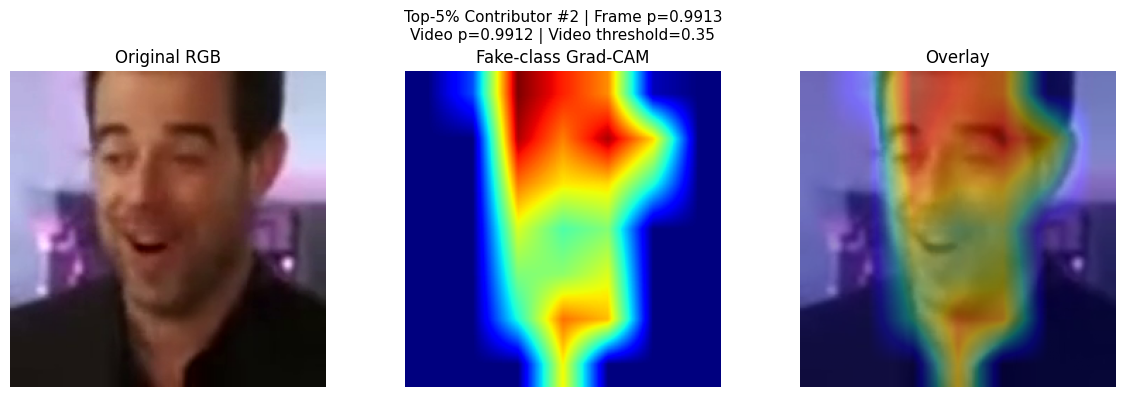


Top-5% Grad-CAM figures saved!
Video: dev/067536.mp4
Output: /kaggle/working/clip_gradcam_dev/top5_contributors


In [22]:
# ============================================================
# CLIP Grad-CAM: Visualize Top-5% Contributors
# ============================================================

top5_output = GRADCAM_OUTPUT / "top5_contributors"
top5_output.mkdir(parents=True, exist_ok=True)

top5_report = []

for rank, (_, example) in enumerate(
    selected_contributors.iterrows(), 1
):

    record = records_lookup[int(example["candidate_id"])]

    original_rgb = reader.read([record])[0][0]

    inputs = clip_processor(
        images=[Image.fromarray(original_rgb)],
        return_tensors="pt"
    )

    pixels = inputs["pixel_values"].to(device)

    heatmaps, probabilities = gradcam_generator.generate(
        pixels
    )

    heatmap = heatmaps[0]
    fake_prob = float(probabilities[0])

    saved_prob = float(example["fake_prob"])
    difference = abs(fake_prob - saved_prob)

    assert difference < 0.01, (
        "Grad-CAM inference differs from saved DEV prediction."
    )

    colour = plt.get_cmap("jet")(heatmap)[..., :3]

    overlay = np.clip(
        0.6 * original_rgb.astype(float) / 255.0
        + 0.4 * colour,
        0, 1
    )

    fig, axes = plt.subplots(1, 3, figsize=(12, 4))

    axes[0].imshow(original_rgb)
    axes[0].set_title("Original RGB")

    axes[1].imshow(
        heatmap,
        cmap="jet",
        vmin=0,
        vmax=1
    )
    axes[1].set_title("Fake-class Grad-CAM")

    axes[2].imshow(overlay)
    axes[2].set_title("Overlay")

    for ax in axes:
        ax.axis("off")

    fig.suptitle(
        f"Top-5% Contributor #{rank} | "
        f"Frame p={fake_prob:.4f}\n"
        f"Video p={recomputed_video_score:.4f} | "
        f"Video threshold={VIDEO_THRESHOLD:.2f}",
        fontsize=11
    )

    plt.tight_layout()

    output_path = (
        top5_output / f"clip_top5_contributor_{rank}.png"
    )

    plt.savefig(
        output_path,
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    top5_report.append({
        "video": selected_video_name,
        "rank": rank,
        "candidate_id": int(example["candidate_id"]),
        "frame_index": int(example["frame_index"]),
        "true_frame_label": int(example["true_label"]),
        "saved_frame_probability": saved_prob,
        "gradcam_frame_probability": fake_prob,
        "video_probability": float(recomputed_video_score),
        "video_threshold": VIDEO_THRESHOLD,
        "top_k": k,
        "figure": str(output_path)
    })

pd.DataFrame(top5_report).to_csv(
    top5_output / "top5_gradcam_report.csv",
    index=False
)

print("\nTop-5% Grad-CAM figures saved!")
print("Video:", selected_video_name)
print("Output:", top5_output)
